In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# scaling, normalization
from sklearn.preprocessing import StandardScaler, MinMaxScaler
# kmeans, dbscan, hierarchical (sklearn)
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
# evaluation
from sklearn.metrics import silhouette_score
# import dataset
from sklearn.datasets import load_iris
# distance matrix (dbscan elbow, hierarchical)
from scipy.spatial.distance import pdist, squareform
# hierarchical (scipy)
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster


# Database
#df = pd.read_csv("DM1_game_dataset.csv")
df = pd.read_csv("/Users/ale/Documents/primo anno/dm1_25_26_dataset/df/DM1_game_dataset.csv")
df = df[df["YearPublished"] != 0]
df = df[df["MinPlayers"] != 0]
df = df[df["MaxPlayers"] != 0]

df = df.dropna()


colonne_rank = [
    "Rank:strategygames", "Rank:abstracts", "Rank:familygames",
    "Rank:thematic", "Rank:cgs", "Rank:wargames",
    "Rank:partygames", "Rank:childrensgames"
]

# Numeriche
numeriche = df.select_dtypes(include=["int64", "float64"]).columns
numeriche = numeriche.drop([
    "BGGId", "Kickstarted", "IsReimplementation"
] + colonne_rank + [
    "Cat:Thematic", "Cat:Strategy", "Cat:War", "Cat:Family", "Cat:CGS",
    "Cat:Abstract", "Cat:Party", "Cat:Childrens"
])

X = df[numeriche]
y = np.array(df['Rating'])


# K means CLustering

# scaling
scaler = MinMaxScaler()
X_minmax = scaler.fit_transform(X)

kmeans = KMeans(n_clusters=20, n_init=10, max_iter=100, random_state=222)
kmeans.fit(X_minmax)

print(f"\nlabels\n{kmeans.labels_}")
print(f"\ncenters\n {kmeans.cluster_centers_}")

centers2 = scaler.inverse_transform(kmeans.cluster_centers_)
print(f"\ncenters descalati\n {centers2}")


labels
[16  3  1 ... 14 14  1]

centers
 [[ 9.97670440e-01  4.11673953e-01  4.29027597e-01  1.32318501e-01
   2.13528034e-02  5.10022674e-01  1.16168974e-01 -6.93889390e-18
   2.96353227e-03  8.86666505e-03  4.03041786e-03  2.49758040e-03
   3.84553734e-03  4.10357848e-03  3.84553734e-03  0.00000000e+00
   1.62658701e-03  0.00000000e+00  8.62812770e-04  2.81030445e-03
   1.16479724e-02]
 [ 9.96668893e-01  6.38413589e-01  6.47023076e-01  1.12044818e-01
   2.22235953e-02  5.80200390e-01  7.64865922e-02  8.16993464e-03
   7.85927297e-03  2.56200461e-02  1.15227511e-02  6.37389062e-03
   8.21296296e-03  7.72668732e-03  8.21296296e-03  5.83566760e-01
   5.24013262e-03  0.00000000e+00  1.39987769e-03  1.12324930e-02
   1.61248710e-02]
 [ 9.97651967e-01  4.87524370e-01  5.01090398e-01  1.27819549e-01
   3.31711632e-02  4.00537051e-01  1.66246448e-02  2.38596491e-01
   6.27433673e-01  4.77286273e-01  5.18454801e-01  5.27687654e-01
   3.14619883e-03  2.80214425e-03  3.14619883e-03  4.86215539e

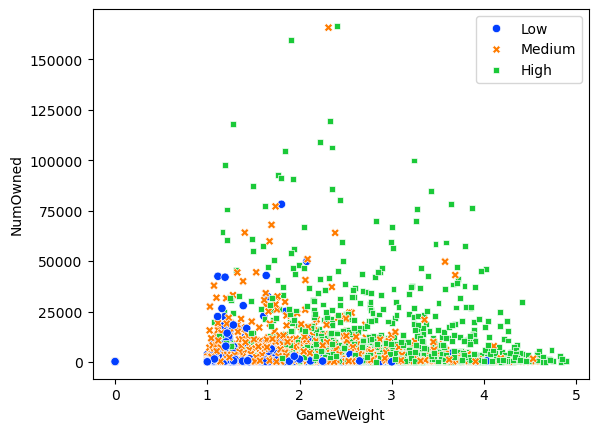

In [9]:
sns.scatterplot(data=df,
                x="GameWeight",
                y="NumOwned",
                hue=y,
                style=y,
                palette="bright")
plt.show()

In [4]:
%%time
sse_list = []

for k in range(2, 51):
    kmeans = KMeans(n_clusters=k, n_init=10, max_iter=100, random_state = 42)
    kmeans.fit(X_minmax)
    sse_list.append(kmeans.inertia_)

CPU times: user 41 s, sys: 36.9 s, total: 1min 17s
Wall time: 9.55 s


In [5]:
%%time
sil_list = []

for k in range(2, 51):
    kmeans = KMeans(n_clusters=k, n_init=10, max_iter=100,random_state = 42)
    kmeans.fit(X_minmax)
    sil_list.append(silhouette_score(X_minmax, kmeans.labels_))

CPU times: user 1min 31s, sys: 1min 56s, total: 3min 28s
Wall time: 22.5 s


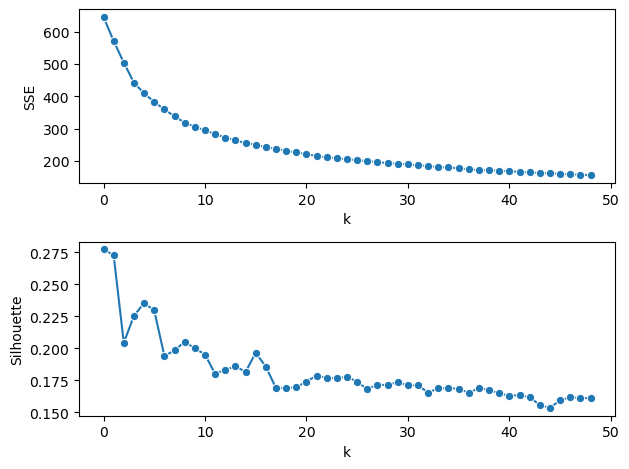

In [6]:
fig, axs = plt.subplots(2)

sns.lineplot(x=range(len(sse_list)), y=sse_list, marker='o', ax=axs[0])
axs[0].set(xlabel='k', ylabel='SSE')

sns.lineplot(x=range(len(sil_list)), y=sil_list, marker='o', ax=axs[1])
axs[1].set(xlabel='k', ylabel='Silhouette')

plt.tight_layout() # Adjust the padding between and around subplots

[[2.00563254e+03 2.93289090e+00 3.13083487e+00 1.78725825e+00
  4.07565415e+00 1.31267929e+01 2.40921820e+02 3.12855518e-01
  1.48407907e+03 5.12667804e+01 2.26126849e+02 4.85460751e+01
  2.48282139e+02 1.42269625e+02 2.48282139e+02 1.12667804e+01
  6.76851536e+02 0.00000000e+00 8.98748578e-01 4.73890785e+00
  4.93174061e-01]
 [1.99915327e+03 3.06170477e+00 3.26512889e+00 1.75376884e+00
  4.63065327e+00 1.17141003e+01 4.36345460e+01 3.56532663e+00
  1.77493216e+04 5.50977387e+02 3.52670603e+03 6.96027638e+02
  1.23442211e+02 7.90829146e+01 1.23442211e+02 1.23819095e+01
  1.26539548e+04 0.00000000e+00 5.06030151e+00 1.15276382e+01
  8.56783920e-01]
 [1.99502117e+03 1.59261374e+00 1.79142553e+00 2.05393528e+00
  6.51977627e+00 8.53070060e+00 1.88029034e+02 7.07151418e-01
  4.02954654e+03 5.87870555e+01 3.61552137e+02 1.21286057e+02
  4.05533360e+01 3.45717139e+01 4.05533360e+01 8.62325210e+00
  2.39472713e+03 0.00000000e+00 4.44186976e+00 2.22453056e+00
  6.91969636e-01]]


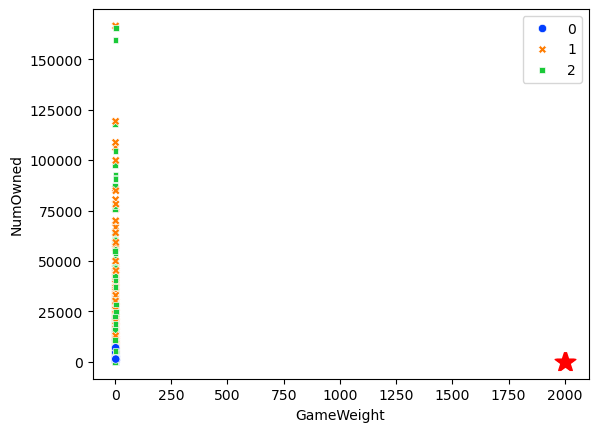

In [11]:
from sklearn.cluster import BisectingKMeans
bkmeans = BisectingKMeans(n_clusters=3, n_init=10, max_iter=100, random_state=94)
bkmeans.fit(X_minmax)

centers = scaler.inverse_transform(bkmeans.cluster_centers_)
print(centers)

sns.scatterplot(data=df,
                x="GameWeight",
                y="NumOwned",
                hue=bkmeans.labels_,
                style=bkmeans.labels_,
                palette="bright",
               )
plt.legend()
plt.scatter(centers[:,0], centers[:,2], c='red', marker='*', s=200)
plt.show()